# **FIFA World Cup Qatar 2022 — Statistical Analysis**

Análisis de los eventos registrados durante los 64 partidos del Mundial de Qatar 2022 mediante MongoDB y Python.

**Fuente:** [StatsBomb Open Data](https://github.com/hudl/open-data).

**Datos:** 64 partidos y 234,637 eventos, almacenados en las colecciones `ffwc_matches` y `ffwc_events`, relacionadas mediante `match_id`.

**Herramientas:** MongoDB, PyMongo, Pandas, Matplotlib y mplsoccer.

Instalación de las librerías necesarias para ejecutar este notebook: `python -m pip install -r requirements.txt`

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D
from pymongo import MongoClient

from mplsoccer import Pitch

conn = MongoClient("mongodb://localhost:27017/")

db = conn["trabajo_final"]
ffwc_matches = db["ffwc_matches"]

# **1. Importando datos**

## **1.1 Matches**

In [2]:
file_path = "../datasets/matches/fifa_world_cup_2022.json"

with open(file_path, encoding="utf-8") as f:
    matches = json.load(f)

ffwc_matches.create_index("match_id", unique=True)

if ffwc_matches.count_documents({}) == 0:
    ffwc_matches.insert_many(matches)
    print("Imported matches:", ffwc_matches.count_documents({}))
else:
    print("✅ Already imported matches:", ffwc_matches.count_documents({}))

✅ Already imported matches: 64


## **1.2 Events**

In [3]:
ffwc_events = db["ffwc_events"]

ffwc_events.create_index("id", unique=True)
ffwc_events.create_index("match_id")

events_dir = Path("../datasets/events")

already_loaded = 0

for match in matches:
    match_id = match["match_id"]

    with open(events_dir / f"{match_id}.json", encoding="utf-8") as f:
        events = json.load(f)

    for event in events:
        event["match_id"] = match_id

    existing = ffwc_events.count_documents({"match_id": match_id})

    if existing == len(events):
        already_loaded += 1
        continue
    elif existing > 0:
        raise ValueError(f"Incomplete import detected for match: {match_id}")

    ffwc_events.insert_many(events)

if already_loaded == len(matches):
    print("✅ All events were already imported.")
else:
    print("✅ Import process completed.")

print("Total events:", ffwc_events.count_documents({}))

✅ All events were already imported.
Total events: 234637


# **2. Análisis de las ocasiones de gol más peligrosas del Mundial 2022**


**Metodología.** Se consideran ocasiones de alta peligrosidad aquellos disparos con `statsbomb_xg > 0.60`, excluyendo los penaltis y las tandas de desempate.

El umbral del 60% es un criterio analítico definido para esta investigación, no una clasificación oficial de StatsBomb.

## **2.1 ¿Cuáles fueron las ocasiones de gol más peligrosas del mundial?**

In [7]:
shot_filter = {
    "period": {"$ne": 5},
    "type.name": "Shot",
    "shot.statsbomb_xg": {"$gt": 0.60},
    "shot.type.name": {"$ne": "Penalty"}
}

shot_projection = {
    "_id": False,
    "match_id": True,
    "team.name": True,
    "player.name": True,
    "minute": True,
    "shot.statsbomb_xg": {"$round": ["$shot.statsbomb_xg", 3]},
    "shot.type.name": True,
    "shot.outcome.name": True
}

df_high_xg = pd.json_normalize(ffwc_events.find(shot_filter, shot_projection).sort({"shot.statsbomb_xg": -1}))

df_high_xg = df_high_xg.rename(columns={
    "team.name": "Team",
    "player.name": "Player",
    "minute": "Minute",
    "shot.statsbomb_xg": "xG",
    "shot.outcome.name": "Outcome"
})

df_high_xg[["Team", "Player", "Minute", "xG", "Outcome"]]

,Team,Player,Minute,xG,Outcome
0,Serbia,Aleksandar Mitrović,52,0.897,Goal
1,Cameroon,Jean-Charles Castelletto,28,0.895,Goal
2,Japan,Ao Tanaka,50,0.873,Goal
3,France,Randal Kolo Muani,78,0.852,Goal
4,Ecuador,Enner Remberto Valencia Lastra,48,0.791,Goal
5,France,Olivier Giroud,31,0.779,Goal
6,Switzerland,Breel-Donald Embolo,43,0.727,Goal
7,Uruguay,Giorgian Daniel De Arrascaeta Benedetti,25,0.711,Goal
8,Netherlands,Frenkie de Jong,48,0.688,Goal
9,Croatia,Lovro Majer,93,0.687,Goal


## **2.2 ¿Cuántas ocasiones de alto xG terminaron en gol por selección?**

In [8]:
xg_per_team_match = {
    "$match": shot_filter
}

xg_per_team_group = [
    {
        "$group": {
            "_id": {
                "team": "$team.name",
                "outcome": "$shot.outcome.name"
            },
            "count": {"$sum": 1},
            "total_xg": {"$sum": "$shot.statsbomb_xg"}
        }
    },
    {
        "$group": {
            "_id": "$_id.team",
            "total_shots": {"$sum": "$count"},
            "total_xg": {"$sum": "$total_xg"},
            "outcomes": {
                "$push": {
                    "k": "$_id.outcome",
                    "v": "$count"
                }
            }
        }
    }
]

xg_per_team_replace = {
    "$replaceWith": {
        "team": "$_id",
        "outcomes": {"$arrayToObject": "$outcomes"},
        "total_shots": "$total_shots",
        "total_xg": {"$round": ["$total_xg", 2]}
    }
}

xg_per_team_sort = {"$sort": {"total_xg": -1}}

xg_per_team = list(ffwc_events.aggregate([xg_per_team_match, *xg_per_team_group, xg_per_team_replace, xg_per_team_sort]))

display(xg_per_team)

[{'team': 'Switzerland',
  'outcomes': {'Goal': 2, 'Off T': 1},
  'total_shots': 3,
  'total_xg': 2.06},
 {'team': 'France',
  'outcomes': {'Goal': 2},
  'total_shots': 2,
  'total_xg': 1.63},
 {'team': 'England',
  'outcomes': {'Goal': 1, 'Off T': 1},
  'total_shots': 2,
  'total_xg': 1.24},
 {'team': 'Serbia',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.9},
 {'team': 'Cameroon',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.89},
 {'team': 'Japan',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.87},
 {'team': 'Ecuador',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.79},
 {'team': 'Uruguay',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.71},
 {'team': 'Croatia',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.69},
 {'team': 'Netherlands',
  'outcomes': {'Goal': 1},
  'total_shots': 1,
  'total_xg': 0.69},
 {'team': 'Canada',
  'outcomes': {'Off T': 1},
  'total_shots': 1,
  'total_xg': 

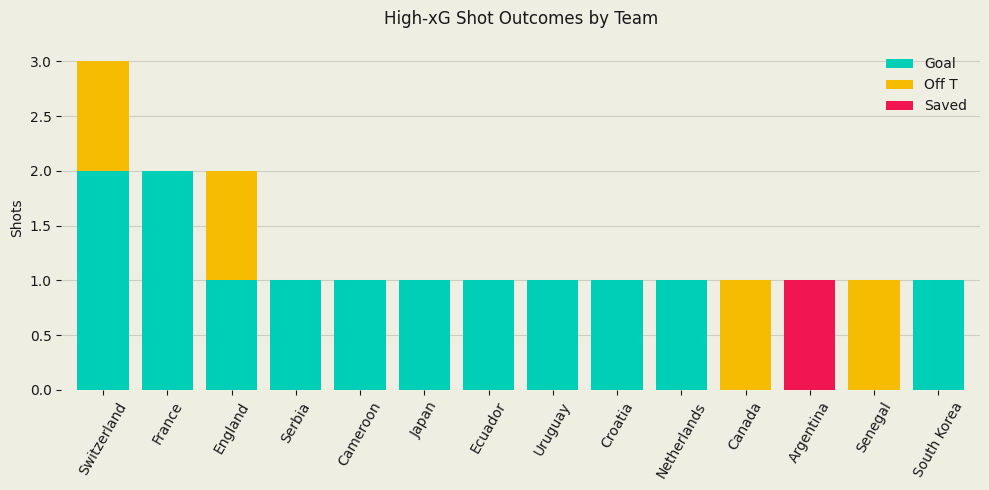

In [9]:
df_xg_per_team = pd.DataFrame([
    {
        "team": doc["team"],
        "outcome": outcome,
        "shots": count,
        "total_xg": doc["total_xg"]
    }
    for doc in xg_per_team
    for outcome, count in doc["outcomes"].items()
])

df_pivot = df_xg_per_team.pivot(index="team", columns="outcome", values="shots").fillna(0)
df_pivot["total_xg"] = df_xg_per_team.groupby("team")["total_xg"].first()

df_plot = df_pivot.sort_values(by="total_xg", ascending=False).drop(columns="total_xg")

color_map = {
    "Goal": "#00cfb7",
    "Off T": "#f5bc01",
    "Saved": "#f11652"
}

burgundy = "#8a1538"
cream = "#efeee3"

ax = df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=color_map,
    width=0.8
)

ax.set_facecolor(cream)
ax.figure.set_facecolor(cream)

ax.set_title("High-xG Shot Outcomes by Team", color="#181818", pad=15)
ax.set_xlabel("")
ax.set_ylabel("Shots", color="#181818")

ax.tick_params(colors="#181818")
ax.tick_params(axis="x", labelrotation=60)

ax.grid(axis="y", color="#181818", alpha=0.15)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(frameon=False, labelcolor="#181818")

plt.tight_layout()
plt.show()

## **2.3 ¿Qué porcentaje de estas ocasiones realmente terminaron en gol?**

In [10]:
conversion_match = {
    "$match": shot_filter
}

conversion_group = {
    "$group": {
        "_id": None,
        "total_shots": {"$sum": 1},
        "total_goals": {
            "$sum": {
                "$cond": [
                    {"$eq": ["$shot.outcome.name", "Goal"]}, 1, 0
                ]
            }
        },
        "total_xg": {"$sum": "$shot.statsbomb_xg"}
    }
}

conversion_project = {
    "$project": {
        "_id": False,
        "total_shots": True,
        "total_goals": True,
        "total_xg": True,
        "conversion_rate": {
            "$multiply": [
                {"$divide": ["$total_goals", "$total_shots"]}, 100
            ]
        }
    }
}

prop_goals = ffwc_events.aggregate([conversion_match, conversion_group, conversion_project])

list(prop_goals)

[{'total_shots': 18,
  'total_goals': 13,
  'total_xg': 12.9988034,
  'conversion_rate': 72.22222222222221}]

### **Hallazgos principales**

Se identificaron **18 disparos con xG superior a 0,60**, de los cuales **13 terminaron en gol (72,22%)**. El xG acumulado fue de aproximadamente **13,00 goles esperados**, prácticamente idéntico al número observado.

Suiza registró el mayor número de ocasiones de esta categoría (3 disparos, 2 goles), mientras que Francia convirtió sus 2 ocasiones identificadas.

**Interpretación:** la coincidencia entre goles esperados y observados resulta interesante, pero el tamaño reducido de la muestra no permite concluir que el modelo de xG esté perfectamente calibrado.

# **3. ¿Qué zonas del campo concentran las oportunidades de gol más peligrosas durante el Mundial 2022?**

**Metodología.** Se analizan los disparos no penales mediante sus coordenadas de inicio en el sistema StatsBomb (campo de 120 × 80 unidades).

Las zonas se clasifican según sus límites espaciales:

- **Área chica:** `x >= 114` y `30 <= y <= 50`.
- **Resto del área penal:** `x >= 102` y `18 <= y <= 62`, excluyendo el área chica.
- **Fuera del área penal:** ubicaciones restantes.

Se comparan el volumen de disparos, los goles, el xG promedio y la tasa de conversión.

## **3.1 Filtrando el dataset y extrayendo coordenadas del disparo**

In [11]:
dang_zones_match = {
    "$match": {
        "type.name": "Shot",
        "shot.type.name": {"$ne": "Penalty"},
        "period": {"$ne": 5}
    }
}

dang_zones_project = {
    "$project": {
        "_id": False,
        "x": {"$arrayElemAt": ["$location", 0]},
        "y": {"$arrayElemAt": ["$location", 1]},
        "xG": "$shot.statsbomb_xg",
        "outcome": "$shot.outcome.name"
    }
}

list(ffwc_events.aggregate([dang_zones_match, dang_zones_project]))

[{'x': 96.5, 'y': 40.7, 'xG': 0.038882375, 'outcome': 'Blocked'},
 {'x': 83.9, 'y': 45.0, 'xG': 0.024477394, 'outcome': 'Goal'},
 {'x': 86.8, 'y': 38.4, 'xG': 0.02207015, 'outcome': 'Blocked'},
 {'x': 107.0, 'y': 48.3, 'xG': 0.06158555, 'outcome': 'Wayward'},
 {'x': 113.3, 'y': 34.9, 'xG': 0.27914461, 'outcome': 'Off T'},
 {'x': 97.5, 'y': 54.0, 'xG': 0.022624016, 'outcome': 'Off T'},
 {'x': 107.6, 'y': 53.2, 'xG': 0.10405799, 'outcome': 'Goal'},
 {'x': 107.9, 'y': 34.2, 'xG': 0.09711841, 'outcome': 'Blocked'},
 {'x': 106.8, 'y': 46.7, 'xG': 0.094470315, 'outcome': 'Wayward'},
 {'x': 105.1, 'y': 41.2, 'xG': 0.051903803, 'outcome': 'Off T'},
 {'x': 112.2, 'y': 37.7, 'xG': 0.086874224, 'outcome': 'Post'},
 {'x': 118.8, 'y': 41.6, 'xG': 0.638813, 'outcome': 'Off T'},
 {'x': 115.4, 'y': 29.4, 'xG': 0.23307544, 'outcome': 'Off T'},
 {'x': 101.1, 'y': 55.3, 'xG': 0.028282227, 'outcome': 'Saved'},
 {'x': 113.4, 'y': 49.1, 'xG': 0.06697492, 'outcome': 'Off T'},
 {'x': 110.5, 'y': 40.7, 'xG': 0

## **3.2 Clasificación de las Zonas de Disparo**

In [12]:
dang_zones_classification = {
    "$addFields": {
        "zone": {
            "$switch": {
                "branches": [
                    {
                        "case": {
                            "$and": [
                                {"$gte": ["$x", 114]},
                                {"$gte": ["$y", 30]},
                                {"$lte": ["$y", 50]}
                            ]
                        },
                        "then": "Area Chica"
                    },
                    {
                        "case": {
                            "$and": [
                                {"$gte": ["$x", 102]},
                                {"$gte": ["$y", 18]},
                                {"$lte": ["$y", 62]}
                            ]
                        },
                        "then": "Resto del área penal"
                    }
                ],
                "default": "Fuera del Area de Penal"
            }
        }
    }
}

danger_shots = list(ffwc_events.aggregate([dang_zones_match, dang_zones_project, dang_zones_classification]))

danger_shots

[{'x': 96.5,
  'y': 40.7,
  'xG': 0.038882375,
  'outcome': 'Blocked',
  'zone': 'Fuera del Area de Penal'},
 {'x': 83.9,
  'y': 45.0,
  'xG': 0.024477394,
  'outcome': 'Goal',
  'zone': 'Fuera del Area de Penal'},
 {'x': 86.8,
  'y': 38.4,
  'xG': 0.02207015,
  'outcome': 'Blocked',
  'zone': 'Fuera del Area de Penal'},
 {'x': 107.0,
  'y': 48.3,
  'xG': 0.06158555,
  'outcome': 'Wayward',
  'zone': 'Resto del área penal'},
 {'x': 113.3,
  'y': 34.9,
  'xG': 0.27914461,
  'outcome': 'Off T',
  'zone': 'Resto del área penal'},
 {'x': 97.5,
  'y': 54.0,
  'xG': 0.022624016,
  'outcome': 'Off T',
  'zone': 'Fuera del Area de Penal'},
 {'x': 107.6,
  'y': 53.2,
  'xG': 0.10405799,
  'outcome': 'Goal',
  'zone': 'Resto del área penal'},
 {'x': 107.9,
  'y': 34.2,
  'xG': 0.09711841,
  'outcome': 'Blocked',
  'zone': 'Resto del área penal'},
 {'x': 106.8,
  'y': 46.7,
  'xG': 0.094470315,
  'outcome': 'Wayward',
  'zone': 'Resto del área penal'},
 {'x': 105.1,
  'y': 41.2,
  'xG': 0.0519038

## **3.3 ¿Qué zonas del campo concentraron más goles y mayor peligro?**

In [13]:
final_projection = {
    "$project": {
        "_id": False,
        "zone": "$_id",
        "total_shots": True,
        "total_goals": True,
        "avg_xG_pct": {
            "$round": [
                {"$multiply": ["$avg_xG", 100]}, 2
                ]
            },
        "conversion_rate": {
            "$round": [
                {
                    "$multiply": [
                        {"$divide": ["$total_goals", "$total_shots"]}, 100
                    ]
                }, 2
            ]
        }
    }
}

dang_zones_group = {
    "$group": {
        "_id": "$zone",
        "total_shots": {"$sum": 1},
        "total_goals": {
            "$sum": {
                "$cond": [
                    {"$eq": ["$outcome", "Goal"]}, 1, 0
                ]
            }
        },
        "avg_xG": {"$avg": "$xG"}
    }
}

final_sort = {"$sort": {"avg_xG_pct": -1}}

zone_summary = list(ffwc_events.aggregate(
    [
        dang_zones_match,
        dang_zones_project,
        dang_zones_classification,
        dang_zones_group,
        final_projection,
        final_sort
    ]
))

zone_summary

[{'total_shots': 116,
  'total_goals': 33,
  'zone': 'Area Chica',
  'avg_xG_pct': 28.7,
  'conversion_rate': 28.45},
 {'total_shots': 772,
  'total_goals': 107,
  'zone': 'Resto del área penal',
  'avg_xG_pct': 11.13,
  'conversion_rate': 13.86},
 {'total_shots': 542,
  'total_goals': 12,
  'zone': 'Fuera del Area de Penal',
  'avg_xG_pct': 3.44,
  'conversion_rate': 2.21}]

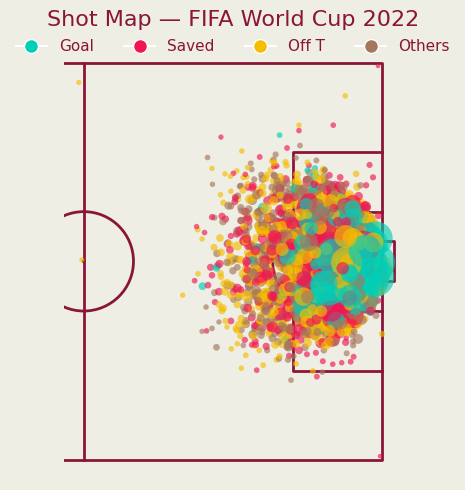

In [14]:
df_zone_shots = pd.DataFrame(danger_shots)

color_map = {
    "Goal": "#00cfb7",
    "Saved": "#f11652",
    "Off T": "#f5bc01"
}

df_zone_shots["color"] = df_zone_shots["outcome"].map(color_map).fillna("#a5775d")
df_zone_shots["size"] = df_zone_shots["xG"] * 900 + 10

pitch = Pitch(
    pitch_type="statsbomb",
    pitch_color="#eeeee4",
    line_color="#8a1538",
    linewidth=2,
    goal_type="box",
    half=True
)

fig, ax = pitch.draw(figsize=(7, 5))
fig.set_facecolor("#eeeee4")

pitch.scatter(
    df_zone_shots["x"],
    df_zone_shots["y"],
    s=df_zone_shots["size"],
    c=df_zone_shots["color"],
    alpha=0.65,
    edgecolors="none",
    ax=ax
)

ax.set_title(
    "Shot Map — FIFA World Cup 2022",
    color="#8a1538",
    fontsize=16,
    pad=12
)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Goal', markerfacecolor="#00cfb7", markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Saved', markerfacecolor="#f11652", markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Off T', markerfacecolor="#f5bc01", markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Others', markerfacecolor="#a5775d", markersize=10),
]

leg = ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=4,
    frameon=False,
    fontsize=11
)

for text in leg.get_texts():
    text.set_color("#8a1538")

plt.show()

### **Hallazgos principales**

Se analizaron **1.430 disparos no penales**, distribuidos en tres zonas:

<div align="center">

| Zona | Disparos | Goles | xG promedio | Conversión |
|---|---:|---:|---:|---:|
| Área chica | 116 | 33 | 28.70% | 28.45% |
| Resto del área penal | 772 | 107 | 11.13% | 13.86% |
| Fuera del área penal | 542 | 12 | 3.44% | 2.21% |

</div>

**Interpretación:** los disparos más próximos a la portería presentan mayor peligrosidad estimada y mayor conversión observada. El área chica registra la mayor proporción de goles por disparo, mientras que el resto del área penal concentra el mayor número absoluto de goles.

# **4. ¿Atacar más significa ganar?**

**Metodología.** La iniciativa ofensiva se aproxima mediante **dos indicadores** por selección y partido:

- **Posesiones en el último tercio:** número de secuencias distintas con al menos una acción ofensiva válida registrada desde `x >= 80`.
- **Disparos:** total de remates no penales, independientemente de su ubicación.

Se considera que una selección **lideró ambos indicadores** únicamente cuando supera estrictamente a su rival en las dos métricas. Los demás casos se clasifican como `No clear leader`.

Estos indicadores miden actividad ofensiva registrada, no dominio táctico completo ni calidad de las oportunidades.

## **4.1 ¿Qué selección mostró mayor iniciativa ofensiva en cada partido?**

In [15]:
is_attack = {
    "$and": [
        {"$gte": [{"$arrayElemAt": [{"$ifNull": ["$location", []]}, 0]}, 80]},
        {"$eq": ["$team.name", "$possession_team.name"]},
        {"$or": [
            {"$ne": ["$type.name", "Ball Receipt*"]},
            {"$ne": [
                {"$ifNull": ["$ball_receipt.outcome.name", None]},
                "Incomplete"
            ]}
        ]}
    ]
}

def team_stats(side):
    return {
        "$arrayElemAt": [
            {"$filter": {
                "input": "$teams",
                "as": "t",
                "cond": {
                    "$eq": [
                        "$$t.team",
                        f"$match_info.{side}_team.{side}_team_name"
                    ]
                }
            }},
            0
        ]
    }

def leads(a, b):
    return {
        "$and": [
            {"$gt": [
                f"${a}.final_third_possession",
                f"${b}.final_third_possession"
            ]},
            {"$gt": [
                f"${a}.total_shots",
                f"${b}.total_shots"
            ]}
        ]
    }

offensive_pipeline = [
    {"$match": {
        "period": {"$ne": 5},
        "shot.type.name": {"$ne": "Penalty"},
        "type.name": {
            "$in": ["Pass", "Carry", "Shot", "Dribble", "Ball Receipt*"]
        }
    }},

    {"$group": {
        "_id": {"match_id": "$match_id", "team": "$team.name"},
        "possession_ids": {
            "$addToSet": {"$cond": [is_attack, "$possession", None]}
        },
        "total_shots": {
            "$sum": {"$cond": [{"$eq": ["$type.name", "Shot"]}, 1, 0]}
        }
    }},

    {"$project": {
        "_id": 0,
        "match_id": "$_id.match_id",
        "team": "$_id.team",
        "final_third_possession": {
            "$size": {"$setDifference": ["$possession_ids", [None]]}
        },
        "total_shots": 1
    }},

    {"$group": {
        "_id": "$match_id",
        "teams": {"$push": {
            "team": "$team",
            "final_third_possession": "$final_third_possession",
            "total_shots": "$total_shots"
        }}
    }},

    {"$lookup": {
        "from": "ffwc_matches",
        "localField": "_id",
        "foreignField": "match_id",
        "as": "match_info"
    }},

    {"$unwind": "$match_info"},

    {"$project": {
        "_id": 0,
        "match_id": "$_id",
        "home_team": "$match_info.home_team.home_team_name",
        "away_team": "$match_info.away_team.away_team_name",
        "home_score": "$match_info.home_score",
        "away_score": "$match_info.away_score",
        "home_stats": team_stats("home"),
        "away_stats": team_stats("away")
    }},

    {"$set": {
        "offensive_leader": {
            "$switch": {
                "branches": [
                    {
                        "case": leads("home_stats", "away_stats"),
                        "then": "Home"
                    },
                    {
                        "case": leads("away_stats", "home_stats"),
                        "then": "Away"
                    }
                ],
                "default": "No clear leader"
            }
        }
    }},

    {"$sort": {"match_id": 1}}
]

offensive_results = list(ffwc_events.aggregate(offensive_pipeline))

updated_matches = 0

for match in offensive_results:
    result = ffwc_matches.update_one(
        {"match_id": match["match_id"]},
        {"$set": {
            "analysis.offensive": {
                "home_stats": match["home_stats"],
                "away_stats": match["away_stats"],
                "leader": match["offensive_leader"]
            }
        }}
    )
    updated_matches += result.matched_count

print("Partidos analizados:", len(offensive_results))
print("Partidos encontrados para actualización:", updated_matches)

display(offensive_results)

Partidos analizados: 64
Partidos encontrados para actualización: 64


[{'match_id': 3857254,
  'home_team': 'Denmark',
  'away_team': 'Tunisia',
  'home_score': 0,
  'away_score': 0,
  'home_stats': {'team': 'Denmark',
   'final_third_possession': 66,
   'total_shots': 11},
  'away_stats': {'team': 'Tunisia',
   'final_third_possession': 32,
   'total_shots': 13},
  'offensive_leader': 'No clear leader'},
 {'match_id': 3857255,
  'home_team': 'Japan',
  'away_team': 'Spain',
  'home_score': 2,
  'away_score': 1,
  'home_stats': {'team': 'Japan',
   'final_third_possession': 17,
   'total_shots': 6},
  'away_stats': {'team': 'Spain',
   'final_third_possession': 44,
   'total_shots': 12},
  'offensive_leader': 'Away'},
 {'match_id': 3857256,
  'home_team': 'Serbia',
  'away_team': 'Switzerland',
  'home_score': 2,
  'away_score': 3,
  'home_stats': {'team': 'Serbia',
   'final_third_possession': 48,
   'total_shots': 12},
  'away_stats': {'team': 'Switzerland',
   'final_third_possession': 37,
   'total_shots': 14},
  'offensive_leader': 'No clear leader'

## **4.2 ¿La superioridad ofensiva estuvo asociada con la victoria?**

In [16]:
home_won = {"$gt": ["$home_score", "$away_score"]}
home_led = {"$eq": ["$analysis.offensive.leader", "Home"]}

outcome_pipeline = [
    {"$match": {
        "analysis.offensive.leader": {"$in": ["Home", "Away"]}
    }},

    {"$set": {
        "leader_outcome": {
            "$cond": [
                {"$eq": ["$home_score", "$away_score"]},
                "Draw",
                {"$cond": [
                    {"$eq": [home_won, home_led]},
                    "Win",
                    "Loss"
                ]}
            ]
        }
    }}
]

outcome_summary = [
    {"$group": {
        "_id": "$leader_outcome",
        "matches": {"$sum": 1}
    }},

    {"$sort": {"matches": -1}},

    {"$group": {
        "_id": None,
        "outcomes": {"$push": {
            "outcome": "$_id",
            "matches": "$matches"
        }},
        "total_matches": {"$sum": "$matches"}
    }},

    {"$project": {
        "_id": 0,
        "results": {
            "$concatArrays": [
                {"$map": {
                    "input": "$outcomes",
                    "as": "o",
                    "in": {
                        "outcome": "$$o.outcome",
                        "matches": "$$o.matches",
                        "percentage": {"$round": [
                            {"$multiply": [
                                {"$divide": ["$$o.matches", "$total_matches"]},
                                100
                            ]},
                            2
                        ]}
                    }
                }},
                [{
                    "outcome": "Total",
                    "matches": "$total_matches",
                    "percentage": 100.0
                }]
            ]
        }
    }},

    {"$unwind": "$results"},
    {"$replaceRoot": {"newRoot": "$results"}}
]

list(ffwc_matches.aggregate(
    outcome_pipeline + outcome_summary
))

[{'outcome': 'Win', 'matches': 21, 'percentage': 48.84},
 {'outcome': 'Loss', 'matches': 15, 'percentage': 34.88},
 {'outcome': 'Draw', 'matches': 7, 'percentage': 16.28},
 {'outcome': 'Total', 'matches': 43, 'percentage': 100.0}]

## **4.3 Derrotas pese a la superioridad ofensiva**

In [17]:
def offensive_difference(metric):
    return {"$abs": {"$subtract": [
        f"$analysis.offensive.home_stats.{metric}",
        f"$analysis.offensive.away_stats.{metric}"
    ]}}

offensive_losses_pipeline = [
    {"$match": {"leader_outcome": "Loss"}},

    {"$project": {
        "_id": 0,
        "match": {"$concat": [
            "$home_team.home_team_name", " vs ", "$away_team.away_team_name"
        ]},
        "score": {"$concat": [
            {"$toString": "$home_score"}, " - ",
            {"$toString": "$away_score"}
        ]},
        "offensive_leader": {"$cond": [
            {"$eq": ["$analysis.offensive.leader", "Home"]},
            "$home_team.home_team_name",
            "$away_team.away_team_name"
        ]},
        "possession_diff": offensive_difference("final_third_possession"),
        "shot_diff": offensive_difference("total_shots")
    }},

    {"$sort": {"shot_diff": -1, "possession_diff": -1}}
]

list(ffwc_matches.aggregate(
    outcome_pipeline + offensive_losses_pipeline
))

[{'match': 'South Korea vs Ghana',
  'score': '2 - 3',
  'offensive_leader': 'South Korea',
  'possession_diff': 24,
  'shot_diff': 14},
 {'match': 'Cameroon vs Brazil',
  'score': '1 - 0',
  'offensive_leader': 'Brazil',
  'possession_diff': 24,
  'shot_diff': 14},
 {'match': 'Germany vs Japan',
  'score': '1 - 2',
  'offensive_leader': 'Germany',
  'possession_diff': 33,
  'shot_diff': 13},
 {'match': 'Belgium vs Canada',
  'score': '1 - 0',
  'offensive_leader': 'Canada',
  'possession_diff': 24,
  'shot_diff': 12},
 {'match': 'Argentina vs Saudi Arabia',
  'score': '1 - 2',
  'offensive_leader': 'Argentina',
  'possession_diff': 17,
  'shot_diff': 11},
 {'match': 'Japan vs Costa Rica',
  'score': '0 - 1',
  'offensive_leader': 'Japan',
  'possession_diff': 36,
  'shot_diff': 9},
 {'match': 'Netherlands vs United States',
  'score': '3 - 1',
  'offensive_leader': 'United States',
  'possession_diff': 24,
  'shot_diff': 7},
 {'match': 'Poland vs Saudi Arabia',
  'score': '2 - 0',
  '

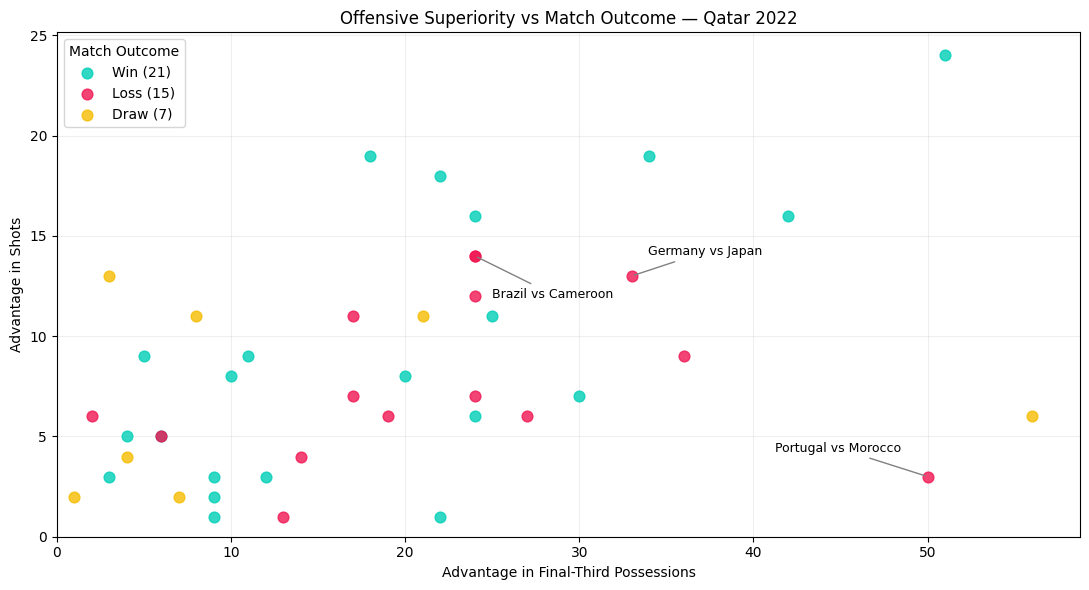

In [18]:
scatter_data = list(ffwc_matches.aggregate(outcome_pipeline + [
    {"$project": {
        "_id": 0,
        "home_team": "$home_team.home_team_name",
        "away_team": "$away_team.away_team_name",
        "outcome": "$leader_outcome",
        "possession_diff": {"$abs": {"$subtract": [
            "$analysis.offensive.home_stats.final_third_possession",
            "$analysis.offensive.away_stats.final_third_possession"
        ]}},
        "shot_diff": {"$abs": {"$subtract": [
            "$analysis.offensive.home_stats.total_shots",
            "$analysis.offensive.away_stats.total_shots"
        ]}}
    }}
]))

colors = {"Win": "#00cfb7", "Loss": "#f11652", "Draw": "#f5bc01"}

highlights = {
    ("Cameroon", "Brazil"): ("Brazil vs Cameroon", (12, -30)),
    ("Germany", "Japan"): ("Germany vs Japan", (12, 15)),
    ("Morocco", "Portugal"): ("Portugal vs Morocco", (-110, 18))
}

fig, ax = plt.subplots(figsize=(11, 6))

for outcome, color in colors.items():
    points = [p for p in scatter_data if p["outcome"] == outcome]
    ax.scatter(
        [p["possession_diff"] for p in points],
        [p["shot_diff"] for p in points],
        label=f"{outcome} ({len(points)})",
        color=color, s=60, alpha=0.8, zorder=3
    )

for p in scatter_data:
    highlight = highlights.get((p["home_team"], p["away_team"]))
    if highlight:
        label, offset = highlight
        ax.annotate(
            label,
            (p["possession_diff"], p["shot_diff"]),
            xytext=offset,
            textcoords="offset points",
            fontsize=9,
            arrowprops={"arrowstyle": "-", "color": "gray"},
            ha="left"
        )

ax.set(
    title="Offensive Superiority vs Match Outcome — Qatar 2022",
    xlabel="Advantage in Final-Third Possessions",
    ylabel="Advantage in Shots",
    xlim=(0, None),
    ylim=(0, None)
)

ax.legend(title="Match Outcome", loc="upper left")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### **Hallazgos principales**

En **43 de los 64 partidos (67.19%)**, una selección superó a su rival tanto en posesiones con actividad en el último tercio como en disparos no penales. En los **21 encuentros restantes**, no hubo superioridad simultánea en ambos indicadores.

Entre los 43 partidos con líder ofensivo claro, este **ganó el 48.84%**, **perdió el 34.88%** y **empató el 16.28%**. Por tanto, **el 51.16% no terminó en victoria** del equipo ofensivamente superior.

El gráfico muestra victorias, derrotas y empates incluso con ventajas ofensivas considerables. Destacan **Brasil (21 disparos frente a 7 de Camerún)**, **Alemania (25 frente a 12 de Japón)** y **Portugal (71 posesiones ofensivas frente a 21 de Marruecos)**, que perdieron pese a liderar ambos indicadores.

**Interpretación:** una mayor actividad ofensiva no garantiza la victoria, y el gráfico no evidencia una relación visual clara entre la magnitud de esa superioridad y el resultado. El volumen ofensivo no refleja necesariamente la calidad de las ocasiones ni la efectividad de las finalizaciones. Estos resultados son descriptivos y no permiten establecer causalidad.